# Duolingo: Optimising Vocabulary Retention Through Spaced Repetition

## Objective
Analyse Word Recall Rate and understand how recall changes across lag, prior exposure, words, languages, parts of speech, and courses.

In [ ]:
print("hello world")

hello world


In [ ]:
!pip install gdown

In [ ]:
import gdown

In [ ]:
import pandas as pd

In [ ]:
import pandas as pd

df = pd.read_csv("forgetting_curve.csv")

df.head()


,learning_language,language_name,lag_bin,lag_bin_order,practice_bin,practice_bin_order,n_traces,avg_session_recall,item_recall_rate,pct_perfect_sessions
0,all,All languages,<1 hour,0,1-2 exposures,0,383261,0.9157,0.9191,87.37
1,all,All languages,<1 hour,0,3-4 exposures,1,893452,0.9137,0.9177,86.26
2,all,All languages,<1 hour,0,5-9 exposures,2,1429269,0.9129,0.9186,86.50
3,all,All languages,<1 hour,0,10-19 exposures,3,1023779,0.9129,0.9199,86.00
4,all,All languages,<1 hour,0,20+ exposures,4,1239541,0.8995,0.9097,84.58


In [ ]:
df.head()

,learning_language,language_name,lag_bin,lag_bin_order,practice_bin,practice_bin_order,n_traces,avg_session_recall,item_recall_rate,pct_perfect_sessions
0,all,All languages,<1 hour,0,1-2 exposures,0,383261,0.9157,0.9191,87.37
1,all,All languages,<1 hour,0,3-4 exposures,1,893452,0.9137,0.9177,86.26
2,all,All languages,<1 hour,0,5-9 exposures,2,1429269,0.9129,0.9186,86.50
3,all,All languages,<1 hour,0,10-19 exposures,3,1023779,0.9129,0.9199,86.00
4,all,All languages,<1 hour,0,20+ exposures,4,1239541,0.8995,0.9097,84.58


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 310 entries, 0 to 309
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   learning_language     310 non-null    object 
 1   language_name         310 non-null    object 
 2   lag_bin               310 non-null    object 
 3   lag_bin_order         310 non-null    int64  
 4   practice_bin          310 non-null    object 
 5   practice_bin_order    310 non-null    int64  
 6   n_traces              310 non-null    int64  
 7   avg_session_recall    310 non-null    float64
 8   item_recall_rate      310 non-null    float64
 9   pct_perfect_sessions  310 non-null    float64
dtypes: float64(3), int64(3), object(4)
memory usage: 24.3+ KB


In [ ]:
df.columns

Index(['learning_language', 'language_name', 'lag_bin', 'lag_bin_order',
       'practice_bin', 'practice_bin_order', 'n_traces', 'avg_session_recall',
       'item_recall_rate', 'pct_perfect_sessions'],
      dtype='object')

In [ ]:
df.describe()

,lag_bin_order,practice_bin_order,n_traces,avg_session_recall,item_recall_rate,pct_perfect_sessions
count,310.000000,310.0000,3.100000e+02,310.000000,310.000000,310.000000
mean,3.935484,2.0000,8.293049e+04,0.888834,0.897956,83.082161
std,2.555981,1.4165,1.573597e+05,0.017793,0.014307,2.836484
min,0.000000,0.0000,6.300000e+01,0.818100,0.851800,72.610000
25%,2.000000,1.0000,1.186825e+04,0.878000,0.888025,81.532500
50%,4.000000,2.0000,3.324150e+04,0.889200,0.898500,83.260000
75%,6.000000,3.0000,8.646775e+04,0.900050,0.905850,84.677500
max,8.000000,4.0000,1.429269e+06,0.932900,0.933700,90.170000


In [ ]:
import os
print(os.listdir())

['.config', 'drive', 'learning_traces_sample.csv', 'language_courses.csv', 'forgetting_curve.csv', 'word_difficulty.csv', 'sample_data']


In [ ]:
import pandas as pd

df2 = pd.read_csv("language_courses.csv")
df3 = pd.read_csv("word_difficulty.csv")
df4 = pd.read_csv("learning_traces_sample.csv")

In [ ]:
print("df:",df.shape)
print("df2:", df2.shape)
print("df3:", df3.shape)
print("df4:", df4.shape)

df: (310, 10)
df2: (8, 11)
df3: (6211, 12)
df4: (499436, 15)


In [ ]:

print("DF2:", df2.columns.tolist())
print("DF3:", df3.columns.tolist())
print("DF4:", df4.columns.tolist())

DF2: ['course', 'ui_language', 'ui_language_name', 'learning_language', 'learning_language_name', 'n_traces', 'n_users', 'avg_session_recall', 'item_recall_rate', 'avg_lag_days', 'avg_prior_exposures']
DF3: ['learning_language', 'language_name', 'surface_form', 'lemma', 'pos', 'grammar_tags', 'n_traces', 'avg_session_recall', 'item_recall_rate', 'avg_prior_exposures', 'difficulty_rank_in_language', 'lexeme_id']
DF4: ['practice_time', 'user_id', 'ui_language', 'learning_language', 'surface_form', 'lemma', 'pos', 'grammar_tags', 'lag_days', 'history_seen', 'history_correct', 'session_seen', 'session_correct', 'p_recall', 'lexeme_id']


In [ ]:
print(df.columns.tolist())
print(df2.columns.tolist())
print(df3.columns.tolist())
print(df4.columns.tolist())

['learning_language', 'language_name', 'lag_bin', 'lag_bin_order', 'practice_bin', 'practice_bin_order', 'n_traces', 'avg_session_recall', 'item_recall_rate', 'pct_perfect_sessions']
['course', 'ui_language', 'ui_language_name', 'learning_language', 'learning_language_name', 'n_traces', 'n_users', 'avg_session_recall', 'item_recall_rate', 'avg_lag_days', 'avg_prior_exposures']
['learning_language', 'language_name', 'surface_form', 'lemma', 'pos', 'grammar_tags', 'n_traces', 'avg_session_recall', 'item_recall_rate', 'avg_prior_exposures', 'difficulty_rank_in_language', 'lexeme_id']
['practice_time', 'user_id', 'ui_language', 'learning_language', 'surface_form', 'lemma', 'pos', 'grammar_tags', 'lag_days', 'history_seen', 'history_correct', 'session_seen', 'session_correct', 'p_recall', 'lexeme_id']


In [ ]:
df2.isnull().sum()
df3.isnull().sum()
df4.isnull().sum()
df.isnull().sum()

,0
learning_language,0
language_name,0
lag_bin,0
lag_bin_order,0
practice_bin,0
practice_bin_order,0
n_traces,0
avg_session_recall,0
item_recall_rate,0
pct_perfect_sessions,0


View the first 5 rows

In [ ]:


print("\nDF2 columns:")
print(df2.columns.tolist())

print("\nDF3 columns:")
print(df3.columns.tolist())

print("\nDF4 columns:")
print(df4.columns.tolist())


DF2 columns:
['course', 'ui_language', 'ui_language_name', 'learning_language', 'learning_language_name', 'n_traces', 'n_users', 'avg_session_recall', 'item_recall_rate', 'avg_lag_days', 'avg_prior_exposures']

DF3 columns:
['learning_language', 'language_name', 'surface_form', 'lemma', 'pos', 'grammar_tags', 'n_traces', 'avg_session_recall', 'item_recall_rate', 'avg_prior_exposures', 'difficulty_rank_in_language', 'lexeme_id']

DF4 columns:
['practice_time', 'user_id', 'ui_language', 'learning_language', 'surface_form', 'lemma', 'pos', 'grammar_tags', 'lag_days', 'history_seen', 'history_correct', 'session_seen', 'session_correct', 'p_recall', 'lexeme_id']


In [ ]:
display(df.head())
display(df2.head())
display(df3.head())
display(df4.head())

,learning_language,language_name,lag_bin,lag_bin_order,practice_bin,practice_bin_order,n_traces,avg_session_recall,item_recall_rate,pct_perfect_sessions
0,all,All languages,<1 hour,0,1-2 exposures,0,383261,0.9157,0.9191,87.37
1,all,All languages,<1 hour,0,3-4 exposures,1,893452,0.9137,0.9177,86.26
2,all,All languages,<1 hour,0,5-9 exposures,2,1429269,0.9129,0.9186,86.50
3,all,All languages,<1 hour,0,10-19 exposures,3,1023779,0.9129,0.9199,86.00
4,all,All languages,<1 hour,0,20+ exposures,4,1239541,0.8995,0.9097,84.58


,course,ui_language,ui_language_name,learning_language,learning_language_name,n_traces,n_users,avg_session_recall,item_recall_rate,avg_lag_days,avg_prior_exposures
0,es -> en,es,Spanish,en,English,3641179,31735,0.8963,0.9039,7.94,39.65
1,en -> es,en,English,es,Spanish,3407689,31155,0.8985,0.9074,10.02,13.07
2,en -> fr,en,English,fr,French,1873734,19947,0.8827,0.8930,8.18,19.46
3,en -> de,en,English,de,German,1452597,14383,0.8928,0.9051,11.08,11.96
4,pt -> en,pt,Portuguese,en,English,949460,8637,0.8987,0.9073,7.14,20.96


,learning_language,language_name,surface_form,lemma,pos,grammar_tags,n_traces,avg_session_recall,item_recall_rate,avg_prior_exposures,difficulty_rank_in_language,lexeme_id
0,de,German,zweiten,zweit,adj,ord;m;sg;acc,292,0.6050,0.6398,5.04,1,f58ba94f5b6a07312e449a9987637f32
1,de,German,ins,in,pr,NaN,115,0.6116,0.6736,7.37,2,360504826f856ea58070939db6aff198
2,de,German,wegen,wegen,pr,dat,109,0.6656,0.7099,6.06,3,c764a035387dc5bad1c5359f786423e0
3,de,German,größeren,groß,adj,comp;mf;pl;acc;mix,233,0.7103,0.7658,6.84,4,066aadf60b6238605b602ffe0279f993
4,de,German,vieles,viel,det,ind;nt;sg;nom,750,0.7179,0.7704,4.96,5,61ed985e99a3bdc4b497a5e0a46b104d


,practice_time,user_id,ui_language,learning_language,surface_form,lemma,pos,grammar_tags,lag_days,history_seen,history_correct,session_seen,session_correct,p_recall,lexeme_id
0,2013-02-28 20:11:37,u:FO,en,de,lernt,lernen,vblex,pri;p3;sg,0.003,14,12,1,0,0.000000,76390c1350a8dac31186187e2fe1e178
1,2013-02-28 20:14:53,u:g3WM,en,pt,leão,leão,n,m;sg,0.017,9,8,1,1,1.000000,4b3613233b3fede2e3e92ac2ef752bf6
2,2013-02-28 20:14:53,u:g3WM,en,pt,roupa,roupa,n,f;*numb,13.791,1,1,1,1,1.000000,3a898602c268f23d8acbeadacc9138be
3,2013-02-28 20:15:21,u:hl1O,en,de,nudeln,nudel,n,f;pl;*case,20.451,2,2,3,2,0.666667,3fb0c6ae83598ec3e6817e2e236e3b9b
4,2013-02-28 20:15:27,u:h5ex,en,de,zucker,zucker,n,m;sg;dat,0.002,2,1,1,1,1.000000,a8f2e402075e0670edf17d20c1329fa9


Check data types

In [ ]:
print("DF:")
print(df.dtypes)

print("\nDF2:")
print(df2.dtypes)

print("\nDF3:")
print(df3.dtypes)

print("\nDF4:")
print(df4.dtypes)

DF:
learning_language        object
language_name            object
lag_bin                  object
lag_bin_order             int64
practice_bin             object
practice_bin_order        int64
n_traces                  int64
avg_session_recall      float64
item_recall_rate        float64
pct_perfect_sessions    float64
dtype: object

DF2:
course                     object
ui_language                object
ui_language_name           object
learning_language          object
learning_language_name     object
n_traces                    int64
n_users                     int64
avg_session_recall        float64
item_recall_rate          float64
avg_lag_days              float64
avg_prior_exposures       float64
dtype: object

DF3:
learning_language               object
language_name                   object
surface_form                    object
lemma                           object
pos                             object
grammar_tags                    object
n_traces                    

## cheak the size of each dataset

In [ ]:
print("DF:", df.shape)
print("DF2:", df2.shape)
print("DF3:", df3.shape)
print("DF4:", df4.shape)

DF: (310, 10)
DF2: (8, 11)
DF3: (6211, 12)
DF4: (499436, 15)


**Average Session Recall by Lag Bin**

In [ ]:
lag_recall = (
    df.groupby('lag_bin', as_index=False)
       .agg(
           avg_session_recall=('avg_session_recall', 'mean')
       )
       .sort_values('lag_bin')
)

lag_recall

,lag_bin,avg_session_recall
0,1-2 weeks,0.887037
1,1-3 days,0.894123
2,1-3 months,0.873394
3,1-6 hours,0.898123
4,2-4 weeks,0.881643
5,3+ months,0.860630
6,3-7 days,0.889534
7,6-24 hours,0.898340
8,<1 hour,0.912649


Plot it

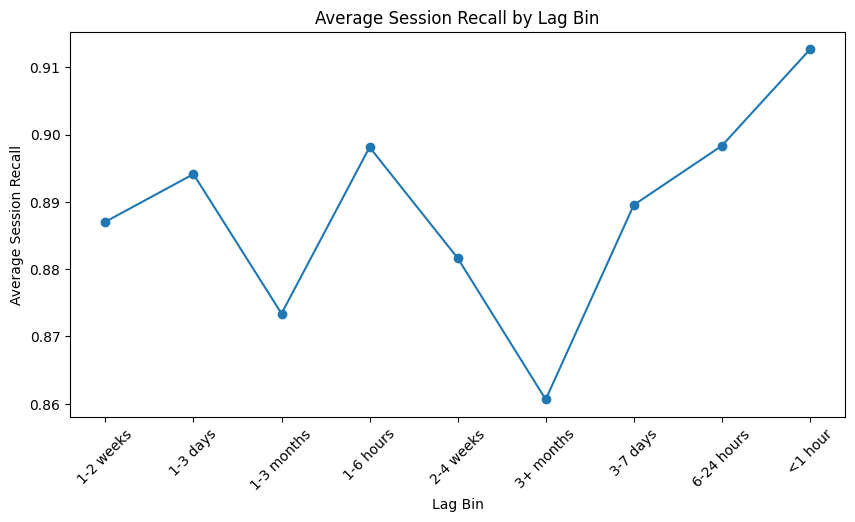

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    lag_recall['lag_bin'],
    lag_recall['avg_session_recall'],
    marker='o'
)

plt.xlabel('Lag Bin')
plt.ylabel('Average Session Recall')
plt.title('Average Session Recall by Lag Bin')
plt.xticks(rotation=45)
plt.show()

In [ ]:
df3.columns.tolist()

['learning_language',
 'language_name',
 'surface_form',
 'lemma',
 'pos',
 'grammar_tags',
 'n_traces',
 'avg_session_recall',
 'item_recall_rate',
 'avg_prior_exposures',
 'difficulty_rank_in_language',
 'lexeme_id']

In [ ]:
word_difficulty = (
    df3.groupby('difficulty_rank_in_language', as_index=False)
       .agg(
           avg_prior_exposures=('avg_prior_exposures', 'mean')
       )
       .sort_values('difficulty_rank_in_language')
)

word_difficulty

,difficulty_rank_in_language,avg_prior_exposures
0,1,43.196667
1,2,27.325000
2,3,8.150000
3,4,16.566667
4,5,10.206667
...,...,...
1589,1778,4.690000
1590,1779,2.020000
1591,1780,4.930000
1592,1781,3.650000


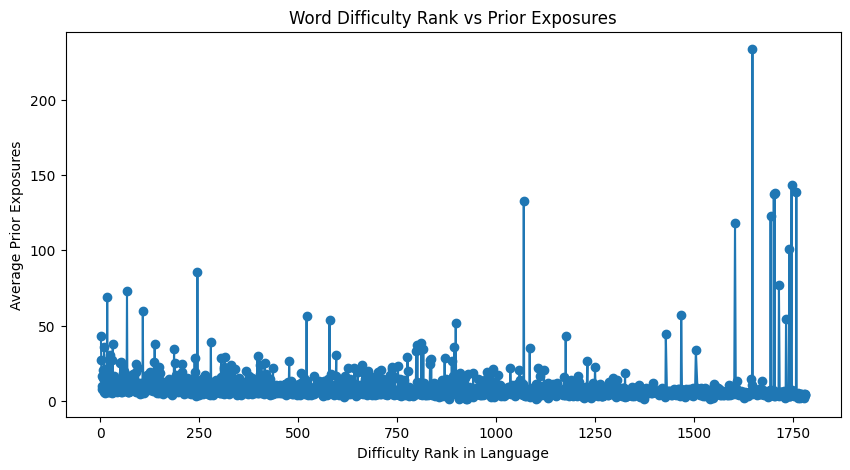

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    word_difficulty['difficulty_rank_in_language'],
    word_difficulty['avg_prior_exposures'],
    marker='o'
)

plt.xlabel('Difficulty Rank in Language')
plt.ylabel('Average Prior Exposures')
plt.title('Word Difficulty Rank vs Prior Exposures')
plt.show()

Course-Level Recall

In [ ]:
print(df.columns.tolist())
print(df2.columns.tolist())
print(df3.columns.tolist())

['learning_language', 'language_name', 'lag_bin', 'lag_bin_order', 'practice_bin', 'practice_bin_order', 'n_traces', 'avg_session_recall', 'item_recall_rate', 'pct_perfect_sessions']
['course', 'ui_language', 'ui_language_name', 'learning_language', 'learning_language_name', 'n_traces', 'n_users', 'avg_session_recall', 'item_recall_rate', 'avg_lag_days', 'avg_prior_exposures']
['learning_language', 'language_name', 'surface_form', 'lemma', 'pos', 'grammar_tags', 'n_traces', 'avg_session_recall', 'item_recall_rate', 'avg_prior_exposures', 'difficulty_rank_in_language', 'lexeme_id']


**Define and deconstruct Word Recall**

*italicized text*What is the overall Word Recall Rate, and how does it vary across lag bin, learning language, part of speech, and course?

## 1. Identifying Relevant Metrics

In [ ]:
print("Forgetting Curve Dataset:")
print(df.columns.tolist())

print("\nLanguage Courses Dataset:")
print(df2.columns.tolist())

print("\nWord Difficulty Dataset:")
print(df3.columns.tolist())

print("\nLearning Traces Dataset:")
print(df4.columns.tolist())

Forgetting Curve Dataset:
['learning_language', 'language_name', 'lag_bin', 'lag_bin_order', 'practice_bin', 'practice_bin_order', 'n_traces', 'avg_session_recall', 'item_recall_rate', 'pct_perfect_sessions']

Language Courses Dataset:
['course', 'ui_language', 'ui_language_name', 'learning_language', 'learning_language_name', 'n_traces', 'n_users', 'avg_session_recall', 'item_recall_rate', 'avg_lag_days', 'avg_prior_exposures']

Word Difficulty Dataset:
['learning_language', 'language_name', 'surface_form', 'lemma', 'pos', 'grammar_tags', 'n_traces', 'avg_session_recall', 'item_recall_rate', 'avg_prior_exposures', 'difficulty_rank_in_language', 'lexeme_id']

Learning Traces Dataset:
['practice_time', 'user_id', 'ui_language', 'learning_language', 'surface_form', 'lemma', 'pos', 'grammar_tags', 'lag_days', 'history_seen', 'history_correct', 'session_seen', 'session_correct', 'p_recall', 'lexeme_id']


## 2. Break Down Word Recall Rate into Actionable Metrics

In [ ]:
key_metrics = [
    'avg_session_recall',
    'item_recall_rate',
    'lag_days',
    'lag_bin',
    'history_seen',
    'learning_language',
    'pos',
    'course',
    'difficulty_rank_in_language',
    'avg_prior_exposures'
]

for metric in key_metrics:
    found_in = []

    for name, df in {
        'df': df,
        'df2': df2,
        'df3': df3,
        'df4': df4
    }.items():
        if metric in df.columns:
            found_in.append(name)

    print(f"{metric}: {found_in}")

avg_session_recall: ['df', 'df2', 'df3']
item_recall_rate: ['df2', 'df3']
lag_days: ['df', 'df4']
lag_bin: []
history_seen: ['df', 'df4']
learning_language: ['df', 'df2', 'df3', 'df4']
pos: ['df', 'df3', 'df4']
course: ['df2']
difficulty_rank_in_language: ['df3']
avg_prior_exposures: ['df2', 'df3']


Recall by Lag Bin

In [ ]:
'lag_bin'

'lag_bin'

In [ ]:
print(df.columns.tolist())

['practice_time', 'user_id', 'ui_language', 'learning_language', 'surface_form', 'lemma', 'pos', 'grammar_tags', 'lag_days', 'history_seen', 'history_correct', 'session_seen', 'session_correct', 'p_recall', 'lexeme_id']


Break down Word Recall Rate

In [ ]:
print(df.columns.tolist())

['practice_time', 'user_id', 'ui_language', 'learning_language', 'surface_form', 'lemma', 'pos', 'grammar_tags', 'lag_days', 'history_seen', 'history_correct', 'session_seen', 'session_correct', 'p_recall', 'lexeme_id']


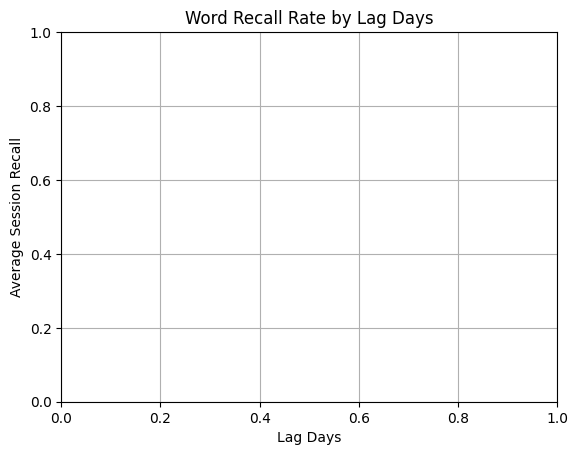

In [ ]:


plt.xlabel("Lag Days")
plt.ylabel("Average Session Recall")
plt.title("Word Recall Rate by Lag Days")
plt.grid(True)
plt.show()

In [ ]:
print(df.columns.tolist())

['practice_time', 'user_id', 'ui_language', 'learning_language', 'surface_form', 'lemma', 'pos', 'grammar_tags', 'lag_days', 'history_seen', 'history_correct', 'session_seen', 'session_correct', 'p_recall', 'lexeme_id']


In [ ]:
df['lag_bin'] = pd.cut(
    df['lag_days'],
    bins=[-1, 1, 3, 7, 14, 30, float('inf')],
    labels=['0-1 days', '2-3 days', '4-7 days',
            '8-14 days', '15-30 days', '30+ days']
)

In [ ]:
df['lag_bin'] = pd.cut(
    df['lag_days'],
    bins=[-1, 1, 3, 7, 14, 30, float('inf')],
    labels=['0-1', '2-3', '4-7', '8-14', '15-30', '30+']
)

In [ ]:
df2.head()

,course,ui_language,ui_language_name,learning_language,learning_language_name,n_traces,n_users,avg_session_recall,item_recall_rate,avg_lag_days,avg_prior_exposures
0,es -> en,es,Spanish,en,English,3641179,31735,0.8963,0.9039,7.94,39.65
1,en -> es,en,English,es,Spanish,3407689,31155,0.8985,0.9074,10.02,13.07
2,en -> fr,en,English,fr,French,1873734,19947,0.8827,0.8930,8.18,19.46
3,en -> de,en,English,de,German,1452597,14383,0.8928,0.9051,11.08,11.96
4,pt -> en,pt,Portuguese,en,English,949460,8637,0.8987,0.9073,7.14,20.96


In [ ]:
print("===== DATASET CHECK =====")

datasets = {
    "df": df,
    "df2": df2,
    "df3": df3,
    "df4": df4
}

for name, data in datasets.items():
    print(f"\n{name}")
    print("Shape:", data.shape)
    print("Columns:")
    for col in data.columns:
        print(" -", repr(col))

===== DATASET CHECK =====

df
Shape: (499436, 16)
Columns:
 - 'practice_time'
 - 'user_id'
 - 'ui_language'
 - 'learning_language'
 - 'surface_form'
 - 'lemma'
 - 'pos'
 - 'grammar_tags'
 - 'lag_days'
 - 'history_seen'
 - 'history_correct'
 - 'session_seen'
 - 'session_correct'
 - 'p_recall'
 - 'lexeme_id'
 - 'lag_bin'

df2
Shape: (8, 11)
Columns:
 - 'course'
 - 'ui_language'
 - 'ui_language_name'
 - 'learning_language'
 - 'learning_language_name'
 - 'n_traces'
 - 'n_users'
 - 'avg_session_recall'
 - 'item_recall_rate'
 - 'avg_lag_days'
 - 'avg_prior_exposures'

df3
Shape: (6211, 12)
Columns:
 - 'learning_language'
 - 'language_name'
 - 'surface_form'
 - 'lemma'
 - 'pos'
 - 'grammar_tags'
 - 'n_traces'
 - 'avg_session_recall'
 - 'item_recall_rate'
 - 'avg_prior_exposures'
 - 'difficulty_rank_in_language'
 - 'lexeme_id'

df4
Shape: (499436, 16)
Columns:
 - 'practice_time'
 - 'user_id'
 - 'ui_language'
 - 'learning_language'
 - 'surface_form'
 - 'lemma'
 - 'pos'
 - 'grammar_tags'
 - 'lag

In [ ]:
print("\n===== FIRST 3 ROWS =====")

for name, data in datasets.items():
    print(f"\n{name}")
    display(data.head(3))


===== FIRST 3 ROWS =====

df


,practice_time,user_id,ui_language,learning_language,surface_form,lemma,pos,grammar_tags,lag_days,history_seen,history_correct,session_seen,session_correct,p_recall,lexeme_id,lag_bin
0,2013-02-28 20:11:37,u:FO,en,de,lernt,lernen,vblex,pri;p3;sg,0.003,14,12,1,0,0.0,76390c1350a8dac31186187e2fe1e178,0-1
1,2013-02-28 20:14:53,u:g3WM,en,pt,leão,leão,n,m;sg,0.017,9,8,1,1,1.0,4b3613233b3fede2e3e92ac2ef752bf6,0-1
2,2013-02-28 20:14:53,u:g3WM,en,pt,roupa,roupa,n,f;*numb,13.791,1,1,1,1,1.0,3a898602c268f23d8acbeadacc9138be,8-14



df2


,course,ui_language,ui_language_name,learning_language,learning_language_name,n_traces,n_users,avg_session_recall,item_recall_rate,avg_lag_days,avg_prior_exposures
0,es -> en,es,Spanish,en,English,3641179,31735,0.8963,0.9039,7.94,39.65
1,en -> es,en,English,es,Spanish,3407689,31155,0.8985,0.9074,10.02,13.07
2,en -> fr,en,English,fr,French,1873734,19947,0.8827,0.8930,8.18,19.46



df3


,learning_language,language_name,surface_form,lemma,pos,grammar_tags,n_traces,avg_session_recall,item_recall_rate,avg_prior_exposures,difficulty_rank_in_language,lexeme_id
0,de,German,zweiten,zweit,adj,ord;m;sg;acc,292,0.6050,0.6398,5.04,1,f58ba94f5b6a07312e449a9987637f32
1,de,German,ins,in,pr,NaN,115,0.6116,0.6736,7.37,2,360504826f856ea58070939db6aff198
2,de,German,wegen,wegen,pr,dat,109,0.6656,0.7099,6.06,3,c764a035387dc5bad1c5359f786423e0



df4


,practice_time,user_id,ui_language,learning_language,surface_form,lemma,pos,grammar_tags,lag_days,history_seen,history_correct,session_seen,session_correct,p_recall,lexeme_id,lag_bin
0,2013-02-28 20:11:37,u:FO,en,de,lernt,lernen,vblex,pri;p3;sg,0.003,14,12,1,0,0.0,76390c1350a8dac31186187e2fe1e178,0-1
1,2013-02-28 20:14:53,u:g3WM,en,pt,leão,leão,n,m;sg,0.017,9,8,1,1,1.0,4b3613233b3fede2e3e92ac2ef752bf6,0-1
2,2013-02-28 20:14:53,u:g3WM,en,pt,roupa,roupa,n,f;*numb,13.791,1,1,1,1,1.0,3a898602c268f23d8acbeadacc9138be,8-14


## 2. Break Down Word Recall Rate into Actionable Metrics

In [ ]:
avg_recall=('avg_session_recall', 'mean')

In [ ]:
print(df.columns.tolist())

['practice_time', 'user_id', 'ui_language', 'learning_language', 'surface_form', 'lemma', 'pos', 'grammar_tags', 'lag_days', 'history_seen', 'history_correct', 'session_seen', 'session_correct', 'p_recall', 'lexeme_id', 'lag_bin']


In [ ]:
recall_by_lag = (
    df.groupby('lag_bin', as_index=False)
      .agg(
          avg_recall=('p_recall', 'mean')
      )
)

display(recall_by_lag)

/tmp/ipykernel_1117/2827439384.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('lag_bin', as_index=False)


,lag_bin,avg_recall
0,0-1,0.906116
1,2-3,0.891813
2,4-7,0.888044
3,8-14,0.881301
4,15-30,0.881116
5,30+,0.871610


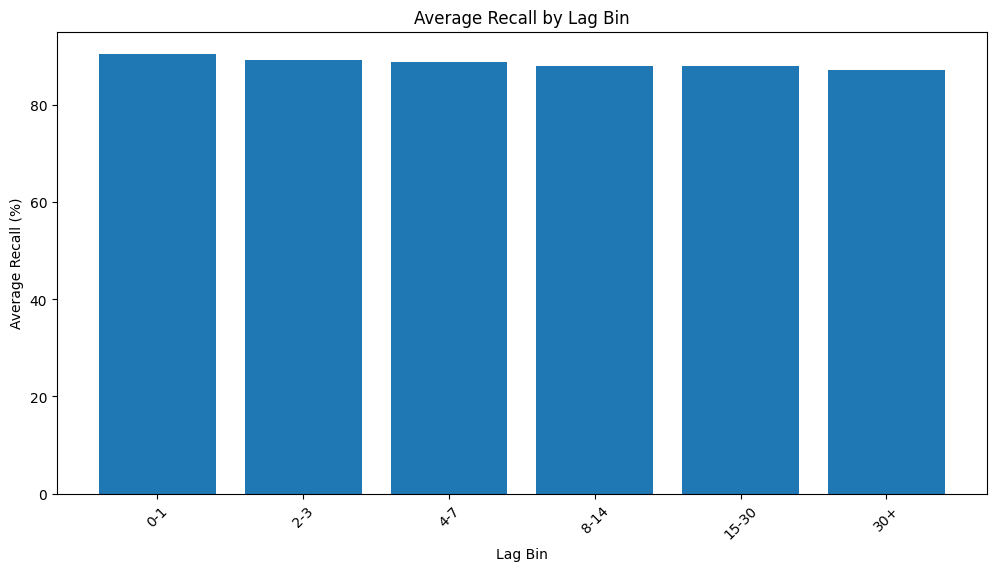

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.bar(
    recall_by_lag['lag_bin'].astype(str),
    recall_by_lag['avg_recall'] * 100
)

plt.xlabel("Lag Bin")
plt.ylabel("Average Recall (%)")
plt.title("Average Recall by Lag Bin")
plt.xticks(rotation=45)
plt.show()

## 3. Defining Specific and Testable Hypotheses

### Hypothesis 1
Word Recall Rate decreases as the time since the last practice increases.

### Hypothesis 2
Word Recall Rate changes with the number of prior exposures.

### Hypothesis 3
Word Recall Rate differs across learning languages.

### Hypothesis 4
Word Recall Rate differs across parts of speech.

### Hypothesis 5
Word difficulty is associated with the number of prior exposures required for recall.

## 4. Understanding Actionable Metrics and Their Relationship with Word Recall Rate

### Business Questions

1. Does recall decrease as the time since last practice increases?
2. Does prior exposure affect recall?
3. Does recall differ across learning languages?
4. Does recall differ across parts of speech?
5. Do difficult words have lower recall?
6. Which course combinations have weaker recall?

### Key Analysis 1: Average Session Recall by Lag Bin

**Business Question:**  
How does Word Recall Rate change as the time since the last practice increases?

**Hypothesis:**  
Word Recall Rate decreases as the time since the last practice increases.

**Metrics:**
- lag_bin
- avg_session_recall
- item_recall_rate
- n_traces

**Dataset:**  
forgetting_curve.csv

In [ ]:
print(df4.columns.tolist())

['practice_time', 'user_id', 'ui_language', 'learning_language', 'surface_form', 'lemma', 'pos', 'grammar_tags', 'lag_days', 'history_seen', 'history_correct', 'session_seen', 'session_correct', 'p_recall', 'lexeme_id', 'lag_bin']


In [ ]:
forgetting_curve_df = pd.read_csv("forgetting_curve.csv")

print(forgetting_curve_df.columns.tolist())

['learning_language', 'language_name', 'lag_bin', 'lag_bin_order', 'practice_bin', 'practice_bin_order', 'n_traces', 'avg_session_recall', 'item_recall_rate', 'pct_perfect_sessions']


In [ ]:
recall_by_lag = (
    forgetting_curve_df.groupby(
        ['lag_bin', 'lag_bin_order'],
        as_index=False
    )
    .agg(
        avg_recall=('avg_session_recall', 'mean'),
        item_recall=('item_recall_rate', 'mean'),
        traces=('n_traces', 'sum')
    )
    .sort_values('lag_bin_order')
)

display(recall_by_lag)

,lag_bin,lag_bin_order,avg_recall,item_recall,traces
8,<1 hour,0,0.912649,0.918697,9938604
3,1-6 hours,1,0.898123,0.904406,1235248
7,6-24 hours,2,0.898340,0.905060,2444542
1,1-3 days,3,0.894123,0.902526,3669576
6,3-7 days,4,0.889534,0.898954,3062616
0,1-2 weeks,5,0.887037,0.896909,2026218
4,2-4 weeks,6,0.881643,0.891229,1582588
2,1-3 months,7,0.873394,0.883291,1263538
5,3+ months,8,0.860630,0.877633,485522


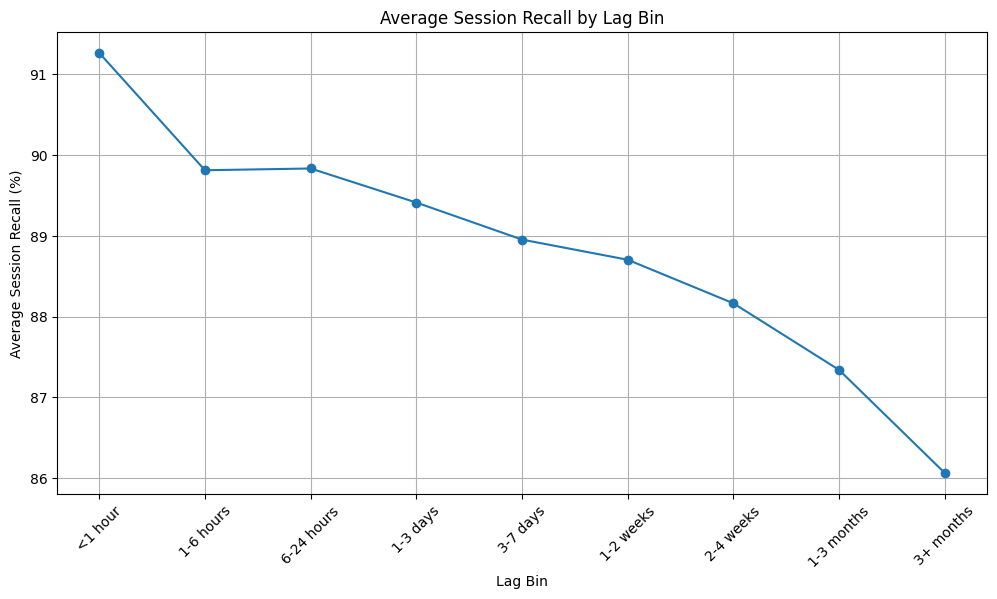

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(
    recall_by_lag['lag_bin'],
    recall_by_lag['avg_recall'] * 100,
    marker='o'
)

plt.xlabel("Lag Bin")
plt.ylabel("Average Session Recall (%)")
plt.title("Average Session Recall by Lag Bin")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

### Key Analysis 2: Average Session Recall by Prior Exposure

**Business Question:**
Does Word Recall Rate improve as the number of prior exposures to a word increases?

**Hypothesis:**
Words with more prior exposures will generally have higher recall rates.

**Metrics:**
- practice_bin
- practice_bin_order
- avg_session_recall
- item_recall_rate
- n_traces

**Dataset:**
forgetting_curve.csv

In [ ]:
recall_by_exposure = (
    forgetting_curve_df.groupby(
        ['practice_bin', 'practice_bin_order'],
        as_index=False
    )
    .agg(
        avg_recall=('avg_session_recall', 'mean'),
        item_recall=('item_recall_rate', 'mean'),
        traces=('n_traces', 'sum')
    )
    .sort_values('practice_bin_order')
)

display(recall_by_exposure)

,practice_bin,practice_bin_order,avg_recall,item_recall,traces
0,1-2 exposures,0,0.886702,0.894492,3432528
3,3-4 exposures,1,0.885635,0.895945,5945528
4,5-9 exposures,2,0.888092,0.897524,6862864
1,10-19 exposures,3,0.891785,0.900748,4540440
2,20+ exposures,4,0.891953,0.901073,4927092


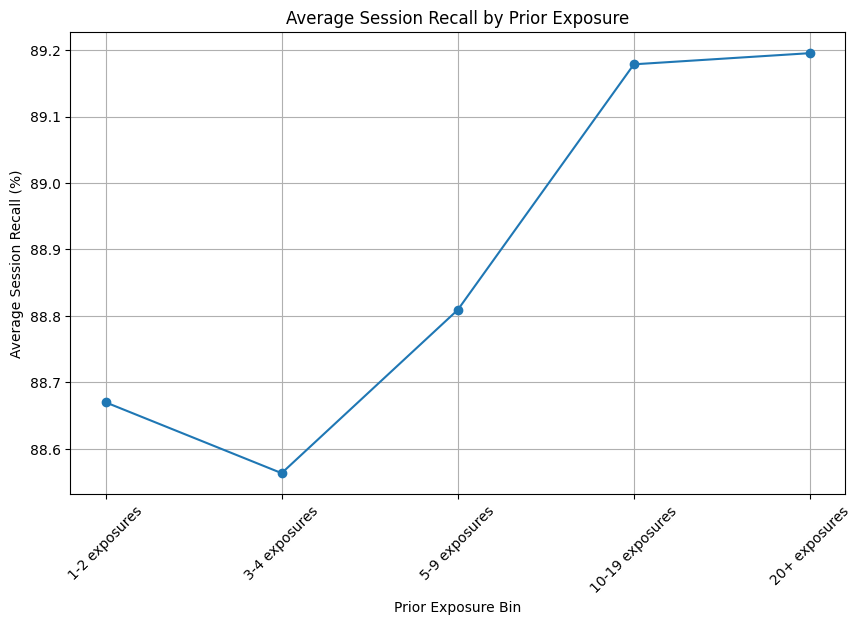

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.plot(
    recall_by_exposure['practice_bin'],
    recall_by_exposure['avg_recall'] * 100,
    marker='o'
)

plt.xlabel("Prior Exposure Bin")
plt.ylabel("Average Session Recall (%)")
plt.title("Average Session Recall by Prior Exposure")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

## Key Analysis 3: Impact of Lag Days on Word Recall Rate

### Business Question
Does Word Recall Rate decrease as the number of days since the previous practice increases?

### Hypothesis
Longer gaps between practice sessions are associated with lower Word Recall Rate.

### Metrics
- lag_days
- p_recall
- session_correct
- session_seen

### Dataset
learning_traces_sample.csv (df)

In [ ]:
lag_days_analysis = (
    df.groupby(
        pd.cut(
            df['lag_days'],
            bins=[0, 1, 3, 7, 14, 30, float('inf')],
            labels=[
                '0-1 day',
                '1-3 days',
                '3-7 days',
                '7-14 days',
                '14-30 days',
                '30+ days'
            ]
        ),
        observed=True
    )
    .agg(
        avg_recall=('p_recall', 'mean'),
        attempts=('session_seen', 'sum'),
        correct=('session_correct', 'sum')
    )
    .reset_index()
)

display(lag_days_analysis)

,lag_days,avg_recall,attempts,correct
0,0-1 day,0.906147,479348,437620
1,1-3 days,0.891813,132342,119216
2,3-7 days,0.888044,112472,100993
3,7-14 days,0.881301,72304,64596
4,14-30 days,0.881116,52673,46918
5,30+ days,0.871610,58542,51694


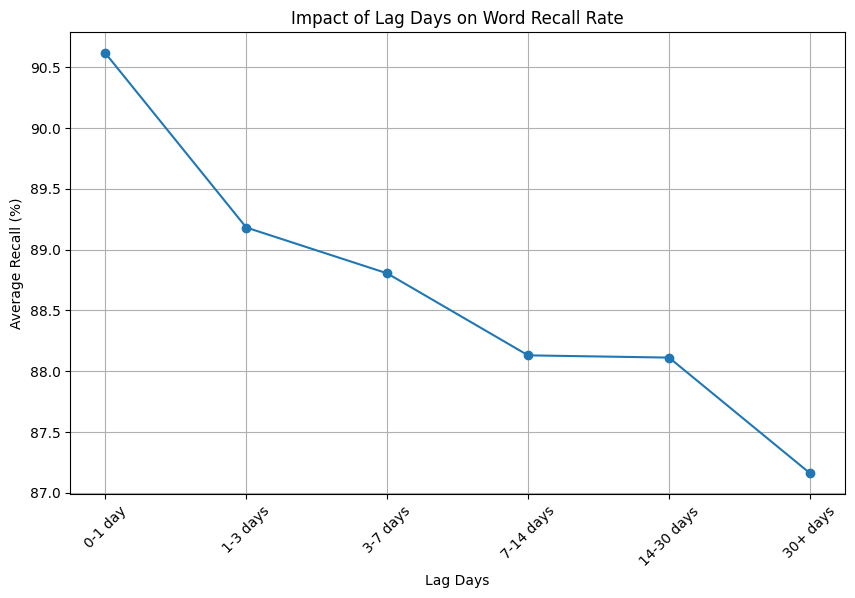

In [ ]:
plt.figure(figsize=(10,6))

plt.plot(
    lag_days_analysis['lag_days'].astype(str),
    lag_days_analysis['avg_recall'] * 100,
    marker='o'
)

plt.xlabel("Lag Days")
plt.ylabel("Average Recall (%)")
plt.title("Impact of Lag Days on Word Recall Rate")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

## Key Analysis 3: Impact of Lag Days on Word Recall Rate

### Business Question
Does Word Recall Rate decrease as the number of days since the previous practice increases?

### Hypothesis
Longer gaps between practice sessions are associated with lower Word Recall Rate.

### Metrics
- lag_days
- p_recall
- session_correct
- session_seen

### Dataset
learning_traces_sample.csv (df)

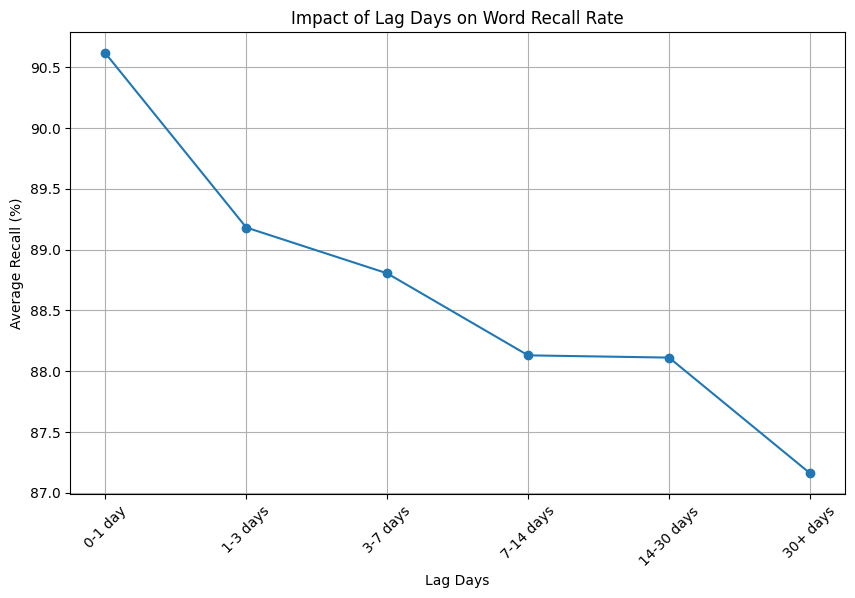

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.plot(
    lag_days_analysis['lag_days'].astype(str),
    lag_days_analysis['avg_recall'] * 100,
    marker='o'
)

plt.xlabel("Lag Days")
plt.ylabel("Average Recall (%)")
plt.title("Impact of Lag Days on Word Recall Rate")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

## Key Analysis 4: Impact of Prior Exposures on Word Recall Rate

### Business Question
How does the number of previous times a word was seen by a learner affect Word Recall Rate?

### Hypothesis
Word Recall Rate increases as the number of prior exposures (history_seen) increases.

### Metrics
- history_seen
- p_recall
- session_correct
- session_seen

### Dataset
learning_traces_sample.csv (df)

In [ ]:
exposure_analysis = (
    df.groupby('history_seen', as_index=False)
      .agg(
          avg_recall=('p_recall', 'mean'),
          attempts=('session_seen', 'sum'),
          correct=('session_correct', 'sum')
      )
      .sort_values('history_seen')
)

display(exposure_analysis.head(20))

,history_seen,avg_recall,attempts,correct
0,1,0.893790,33193,29839
1,2,0.896370,78637,71030
2,3,0.895412,123928,111921
3,4,0.894377,94833,85542
4,5,0.894864,69140,62472
5,6,0.896442,57390,51962
6,7,0.899841,44823,40644
7,8,0.899842,39287,35689
8,9,0.901000,32467,29499
9,10,0.900148,27918,25328


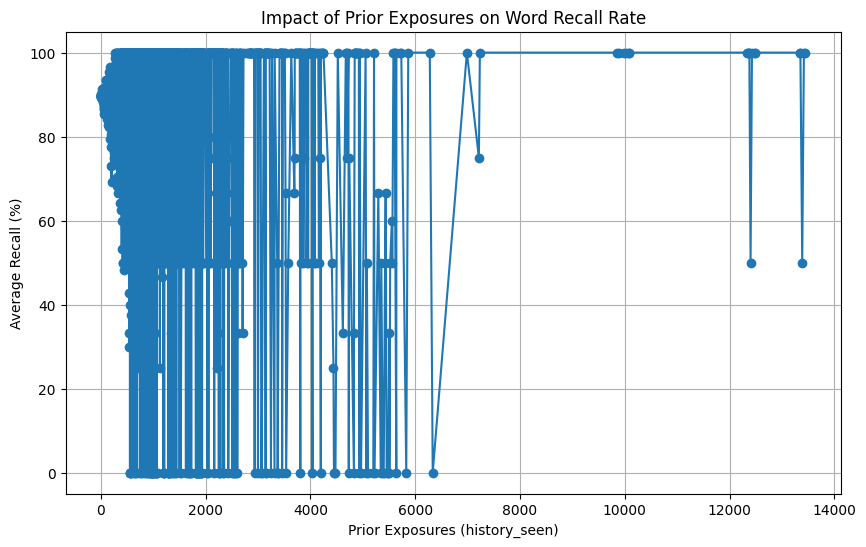

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.plot(
    exposure_analysis['history_seen'],
    exposure_analysis['avg_recall'] * 100,
    marker='o'
)

plt.xlabel("Prior Exposures (history_seen)")
plt.ylabel("Average Recall (%)")
plt.title("Impact of Prior Exposures on Word Recall Rate")
plt.grid(True)

plt.show()

## Key Analysis 5: Word Recall Rate by Learning Language

### Business Question
Which learning languages have the highest and lowest Word Recall Rates?

### Hypothesis
Word Recall Rate differs across learning languages.

### Metrics
- learning_language
- p_recall
- session_correct
- session_seen
- user_id

### Dataset
learning_traces_sample.csv (df)

In [ ]:
language_analysis = (
    df.groupby('learning_language', as_index=False)
      .agg(
          avg_recall=('p_recall', 'mean'),
          attempts=('session_seen', 'sum'),
          correct=('session_correct', 'sum'),
          users=('user_id', 'nunique')
      )
      .sort_values('avg_recall', ascending=False)
)

display(language_analysis)

,learning_language,avg_recall,attempts,correct,users
4,it,0.907936,52505,47809,4362
5,pt,0.904907,20806,18958,1851
1,en,0.898537,359721,325782,29037
2,es,0.897545,238222,216041,20912
0,de,0.892241,100403,90877,9232
3,fr,0.883388,137138,122569,11707


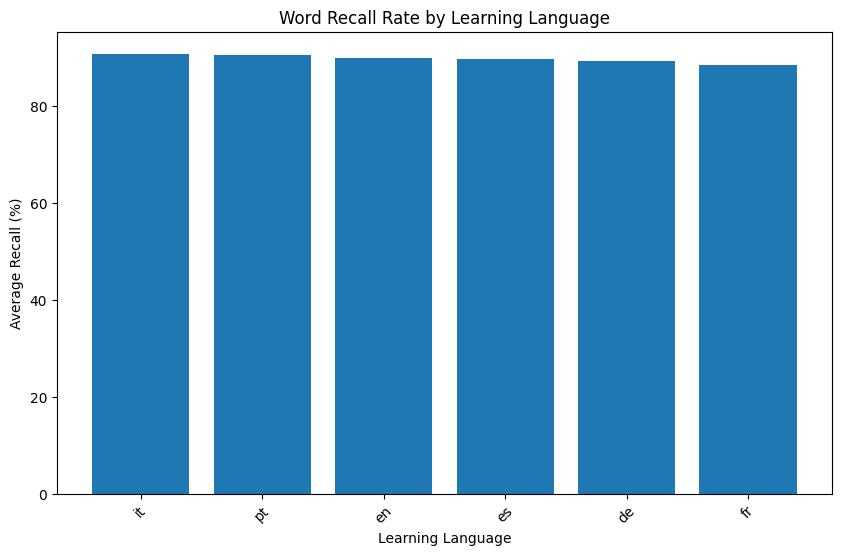

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.bar(
    language_analysis['learning_language'],
    language_analysis['avg_recall'] * 100
)

plt.xlabel("Learning Language")
plt.ylabel("Average Recall (%)")
plt.title("Word Recall Rate by Learning Language")
plt.xticks(rotation=45)

plt.show()

## Key Analysis 6: Word Recall Rate by Part of Speech

### Business Question
Which parts of speech have the highest and lowest Word Recall Rates?

### Hypothesis
Word Recall Rate differs across parts of speech.

### Metrics
- pos
- p_recall
- session_correct
- session_seen

### Dataset
learning_traces_sample.csv (df)

In [ ]:
pos_analysis = (
    df.groupby('pos', as_index=False)
      .agg(
          avg_recall=('p_recall', 'mean'),
          total_attempts=('session_seen', 'sum')
      )
      .sort_values('avg_recall', ascending=False)
)

display(pos_analysis)

,pos,avg_recall,total_attempts
3,@adv:en_fait,1.000000,1
5,@adv:peut_etre,1.000000,7
43,@pr:afin_de,1.000000,2
40,@pr:a_cause_de,1.000000,8
45,@pr:autant_de,1.000000,10
...,...,...,...
1,@adv:au_dela,0.750000,3
46,@pr:plus_de,0.708333,11
2,@adv:au_moins,0.500000,6
19,@cnj:pour_que,0.500000,2


In [ ]:
print(pos_analysis.columns.tolist())

['pos', 'avg_recall', 'total_attempts']


In [ ]:
pos_analysis = (
    df.groupby('pos', as_index=False)
      .agg(
          avg_recall=('p_recall', 'mean'),
          attempts=('session_seen', 'sum'),
          correct=('session_correct', 'sum')
      )
      .sort_values('avg_recall', ascending=False)
)

display(pos_analysis)

,pos,avg_recall,attempts,correct
3,@adv:en_fait,1.000000,1,1
5,@adv:peut_etre,1.000000,7,7
43,@pr:afin_de,1.000000,2,2
40,@pr:a_cause_de,1.000000,8,8
45,@pr:autant_de,1.000000,10,10
...,...,...,...,...
1,@adv:au_dela,0.750000,3,2
46,@pr:plus_de,0.708333,11,8
2,@adv:au_moins,0.500000,6,4
19,@cnj:pour_que,0.500000,2,1


In [ ]:
pos_names = {
    'n': 'Noun',
    'vblex': 'Verb',
    'adj': 'Adj',
    'adv': 'Adv',
    'pr': 'Prep',
    'det': 'Det',
    'prn': 'Pronoun',
    'num': 'Number',
    'cnjcoo': 'Conj',
    'cnjsub': 'Subj',
    'ij': 'Interj'
}

pos_analysis['pos_short'] = (
    pos_analysis['pos']
    .map(pos_names)
    .fillna(pos_analysis['pos'])
)

display(pos_analysis)

,pos,avg_recall,total_attempts,pos_short
3,@adv:en_fait,1.000000,1,@adv:en_fait
5,@adv:peut_etre,1.000000,7,@adv:peut_etre
43,@pr:afin_de,1.000000,2,@pr:afin_de
40,@pr:a_cause_de,1.000000,8,@pr:a_cause_de
45,@pr:autant_de,1.000000,10,@pr:autant_de
...,...,...,...,...
1,@adv:au_dela,0.750000,3,@adv:au_dela
46,@pr:plus_de,0.708333,11,@pr:plus_de
2,@adv:au_moins,0.500000,6,@adv:au_moins
19,@cnj:pour_que,0.500000,2,@cnj:pour_que


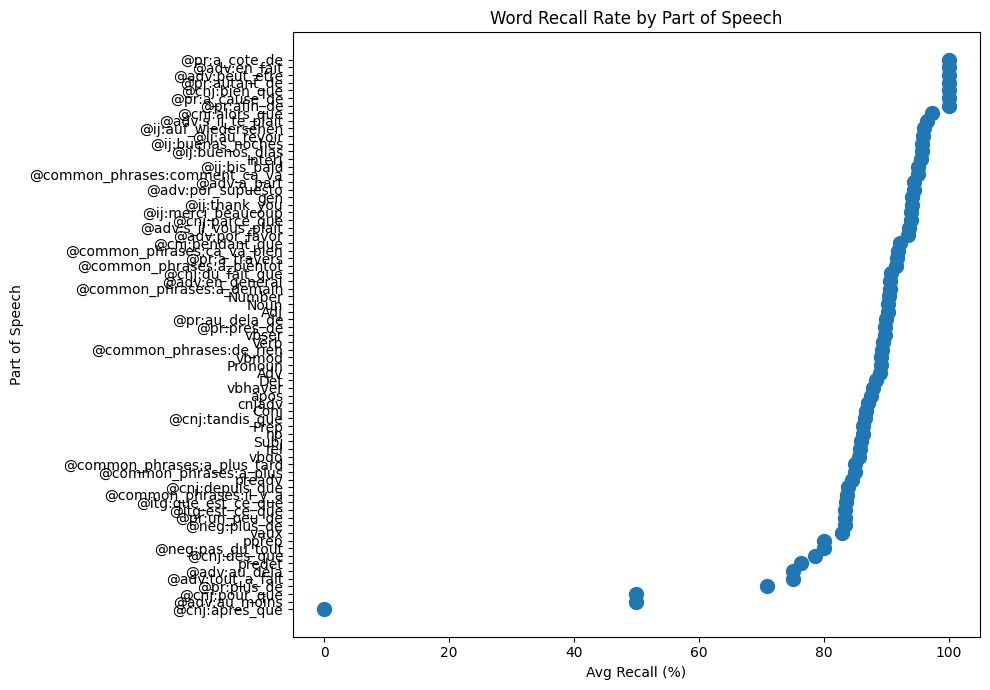

In [ ]:
import matplotlib.pyplot as plt

pos_sorted = pos_analysis.sort_values('avg_recall')

plt.figure(figsize=(10, 7))

plt.scatter(
    pos_sorted['avg_recall'] * 100,
    pos_sorted['pos_short'],
    s=100
)

plt.xlabel("Avg Recall (%)")
plt.ylabel("Part of Speech")
plt.title("Word Recall Rate by Part of Speech")

plt.tight_layout()
plt.show()

## Key Analysis 7: Word Difficulty and Recall

### Business Question
Do difficult words have lower recall rates and require more prior exposures?

### Hypothesis
Words with higher difficulty rankings have lower recall rates and require more prior exposures.

### Metrics
- surface_form
- lemma
- learning_language
- pos
- difficulty_rank_in_language
- avg_prior_exposures
- avg_session_recall
- item_recall_rate

### Dataset
word_difficulty.csv (df3)

In [ ]:
word_difficulty_analysis = (
    df3[
        [
            'learning_language',
            'surface_form',
            'lemma',
            'pos',
            'difficulty_rank_in_language',
            'avg_prior_exposures',
            'avg_session_recall',
            'item_recall_rate'
        ]
    ]
    .sort_values('difficulty_rank_in_language')
)

display(word_difficulty_analysis.head(20))

,learning_language,surface_form,lemma,pos,difficulty_rank_in_language,avg_prior_exposures,avg_session_recall,item_recall_rate
5043,it,ci,ci,prn,1,8.84,0.7061,0.7336
5829,pt,ontem,ontem,adv,1,10.15,0.6902,0.7549
4174,fr,en,en,prn,1,5.81,0.6633,0.6990
1026,en,since,since,pr,1,224.17,0.4590,0.5033
0,de,zweiten,zweit,adj,1,5.04,0.6050,0.6398
2808,es,plantea,plantear,vblex,1,5.17,0.5674,0.5978
4175,fr,moins,moins,adv,2,5.98,0.6977,0.7211
1,de,ins,in,pr,2,7.37,0.6116,0.6736
1027,en,have,have,vbhaver,2,131.37,0.5829,0.6105
2809,es,pensé,pensar,vblex,2,5.95,0.6202,0.6788


In [ ]:
hardest_words = (
    df3.sort_values('difficulty_rank_in_language')
       [
           [
               'learning_language',
               'surface_form',
               'lemma',
               'pos',
               'difficulty_rank_in_language',
               'avg_prior_exposures',
               'item_recall_rate'
           ]
       ]
       .head(20)
)

display(hardest_words)

,learning_language,surface_form,lemma,pos,difficulty_rank_in_language,avg_prior_exposures,item_recall_rate
5043,it,ci,ci,prn,1,8.84,0.7336
5829,pt,ontem,ontem,adv,1,10.15,0.7549
4174,fr,en,en,prn,1,5.81,0.6990
1026,en,since,since,pr,1,224.17,0.5033
0,de,zweiten,zweit,adj,1,5.04,0.6398
2808,es,plantea,plantear,vblex,1,5.17,0.5978
4175,fr,moins,moins,adv,2,5.98,0.7211
1,de,ins,in,pr,2,7.37,0.6736
1027,en,have,have,vbhaver,2,131.37,0.6105
2809,es,pensé,pensar,vblex,2,5.95,0.6788


## Key Analysis 8: Highest and Lowest Recall Words

### Business Question
Which individual words have the highest and lowest Word Recall Rates?

### Hypothesis
Word-level recall varies substantially, with some words consistently easier or harder to recall.

### Metrics
- surface_form
- lemma
- learning_language
- pos
- item_recall_rate
- avg_session_recall
- n_traces

### Dataset
word_difficulty.csv (df3)

In [ ]:
lowest_recall_words = (
    df3[
        [
            'learning_language',
            'surface_form',
            'lemma',
            'pos',
            'item_recall_rate',
            'avg_session_recall',
            'n_traces'
        ]
    ]
    .sort_values('item_recall_rate')
    .head(20)
)

display(lowest_recall_words)

,learning_language,surface_form,lemma,pos,item_recall_rate,avg_session_recall,n_traces
1026,en,since,since,pr,0.5033,0.4590,110
2808,es,plantea,plantear,vblex,0.5978,0.5674,138
1027,en,have,have,vbhaver,0.6105,0.5829,115
0,de,zweiten,zweit,adj,0.6398,0.6050,292
1,de,ins,in,pr,0.6736,0.6116,115
2809,es,pensé,pensar,vblex,0.6788,0.6202,121
1032,en,see,see,vblex,0.6953,0.6826,275
4174,fr,en,en,prn,0.6990,0.6633,544
2810,es,pesar,pesar,vblex,0.7000,0.6508,121
1031,en,drink,drink,vblex,0.7047,0.6814,506


In [ ]:
highest_recall_words = (
    df3[
        [
            'learning_language',
            'surface_form',
            'lemma',
            'pos',
            'item_recall_rate',
            'avg_session_recall',
            'n_traces'
        ]
    ]
    .sort_values('item_recall_rate', ascending=False)
    .head(20)
)

display(highest_recall_words)

,learning_language,surface_form,lemma,pos,item_recall_rate,avg_session_recall,n_traces
2807,en,mine,mine,prn,0.9957,0.9960,249
6210,pt,vocês,você,prn,0.9957,0.9957,231
5827,it,buongiorno,buongiorno,ij,0.9956,0.9956,689
2806,en,activity,activity,n,0.9926,0.9956,113
2801,en,universe,universe,n,0.9926,0.9900,100
6208,pt,olá,olá,ij,0.9926,0.9924,1224
2802,en,level,level,n,0.9918,0.9909,110
5828,it,nave,nave,n,0.9911,0.9967,100
2803,en,adventure,adventure,n,0.9910,0.9918,570
6209,pt,cima,cima,n,0.9904,0.9952,413


## Key Analysis 9: Course-Level Word Recall Rate

### Business Question
Which language-course combinations have the highest and lowest Word Recall Rates?

### Hypothesis
Word Recall Rate differs across course and language-pair combinations.

### Metrics
- course
- ui_language
- learning_language
- item_recall_rate
- avg_session_recall
- n_users
- n_traces

### Dataset
language_courses.csv (df2)

In [ ]:
course_analysis = (
    df2[
        [
            'course',
            'ui_language',
            'learning_language',
            'item_recall_rate',
            'avg_session_recall',
            'n_users',
            'n_traces'
        ]
    ]
    .sort_values('item_recall_rate', ascending=False)
)

display(course_analysis)

,course,ui_language,learning_language,item_recall_rate,avg_session_recall,n_users,n_traces
6,it -> en,it,en,0.9137,0.9096,3436,424152
7,en -> pt,en,pt,0.9121,0.9055,2709,311480
5,en -> it,en,it,0.9117,0.9086,6498,793935
1,en -> es,en,es,0.9074,0.8985,31155,3407689
4,pt -> en,pt,en,0.9073,0.8987,8637,949460
3,en -> de,en,de,0.9051,0.8928,14383,1452597
0,es -> en,es,en,0.9039,0.8963,31735,3641179
2,en -> fr,en,fr,0.8930,0.8827,19947,1873734


In [ ]:
lowest_recall_courses = (
    course_analysis
    .sort_values('item_recall_rate')
    .head(10)
)

display(lowest_recall_courses)

,course,ui_language,learning_language,item_recall_rate,avg_session_recall,n_users,n_traces
2,en -> fr,en,fr,0.8930,0.8827,19947,1873734
0,es -> en,es,en,0.9039,0.8963,31735,3641179
3,en -> de,en,de,0.9051,0.8928,14383,1452597
4,pt -> en,pt,en,0.9073,0.8987,8637,949460
1,en -> es,en,es,0.9074,0.8985,31155,3407689
5,en -> it,en,it,0.9117,0.9086,6498,793935
7,en -> pt,en,pt,0.9121,0.9055,2709,311480
6,it -> en,it,en,0.9137,0.9096,3436,424152


In [ ]:
highest_recall_courses = (
    course_analysis
    .sort_values('item_recall_rate', ascending=False)
    .head(10)
)

display(highest_recall_courses)

,course,ui_language,learning_language,item_recall_rate,avg_session_recall,n_users,n_traces
6,it -> en,it,en,0.9137,0.9096,3436,424152
7,en -> pt,en,pt,0.9121,0.9055,2709,311480
5,en -> it,en,it,0.9117,0.9086,6498,793935
1,en -> es,en,es,0.9074,0.8985,31155,3407689
4,pt -> en,pt,en,0.9073,0.8987,8637,949460
3,en -> de,en,de,0.9051,0.8928,14383,1452597
0,es -> en,es,en,0.9039,0.8963,31735,3641179
2,en -> fr,en,fr,0.8930,0.8827,19947,1873734


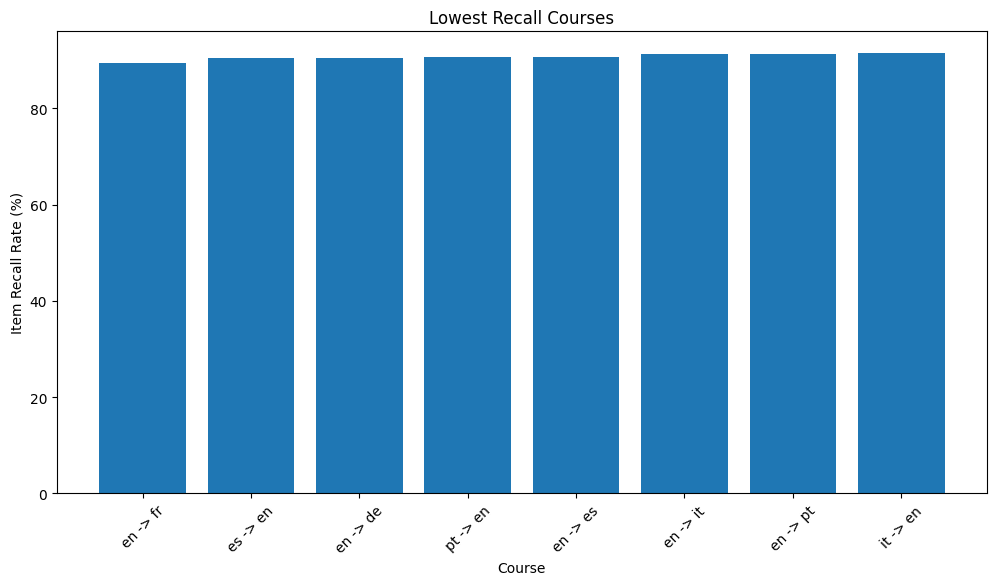

In [ ]:
plt.figure(figsize=(12,6))

plt.bar(
    lowest_recall_courses['course'],
    lowest_recall_courses['item_recall_rate'] * 100
)

plt.xlabel("Course")
plt.ylabel("Item Recall Rate (%)")
plt.title("Lowest Recall Courses")
plt.xticks(rotation=45)

plt.show()

## Key Analysis 10: Learner Practice Behaviour and Word Recall Rate

### Business Question
How does learner practice behaviour relate to Word Recall Rate?

### Hypothesis
Learners with greater prior exposure and more practice activity tend to show different recall performance.

### Metrics
- user_id
- history_seen
- lag_days
- p_recall
- session_seen
- session_correct

### Dataset
learning_traces_sample.csv (df)

In [ ]:
learner_behaviour = (
    df.groupby('user_id', as_index=False)
      .agg(
          total_sessions=('practice_time', 'count'),
          avg_history_seen=('history_seen', 'mean'),
          avg_lag_days=('lag_days', 'mean'),
          avg_recall=('p_recall', 'mean')
      )
)

display(learner_behaviour.head(20))

,user_id,total_sessions,avg_history_seen,avg_lag_days,avg_recall
0,u:--N,1,10.000000,96.603000,1.000000
1,u:--U,1,3.000000,64.916000,1.000000
2,u:-3I,1,2.000000,0.006000,1.000000
3,u:-3n,5,12.400000,142.526600,0.600000
4,u:-4V,8,12.500000,19.094875,0.875000
5,u:-4y,2,15.000000,124.961000,1.000000
6,u:-7F,10,26.400000,5.114800,0.600000
7,u:-7U,1,56.000000,8.676000,1.000000
8,u:-8a,1,4.000000,0.012000,1.000000
9,u:-AA,4,24.000000,12.265250,0.964286


In [ ]:
learner_behaviour['practice_frequency_group'] = pd.qcut(
    learner_behaviour['total_sessions'],
    q=4,
    labels=False,
    duplicates='drop'
)

learner_behaviour['practice_frequency_group'] = (
    learner_behaviour['practice_frequency_group']
    .map({
        0: 'Low',
        1: 'Medium-Low',
        2: 'Medium-High',
        3: 'High'
    })
)

display(learner_behaviour.head(20))

,user_id,total_sessions,avg_history_seen,avg_lag_days,avg_recall,practice_frequency_group
0,u:--N,1,10.000000,96.603000,1.000000,Low
1,u:--U,1,3.000000,64.916000,1.000000,Low
2,u:-3I,1,2.000000,0.006000,1.000000,Low
3,u:-3n,5,12.400000,142.526600,0.600000,Medium-Low
4,u:-4V,8,12.500000,19.094875,0.875000,Medium-High
5,u:-4y,2,15.000000,124.961000,1.000000,Low
6,u:-7F,10,26.400000,5.114800,0.600000,Medium-High
7,u:-7U,1,56.000000,8.676000,1.000000,Low
8,u:-8a,1,4.000000,0.012000,1.000000,Low
9,u:-AA,4,24.000000,12.265250,0.964286,Medium-Low


In [ ]:
practice_frequency_analysis = (
    learner_behaviour
    .groupby('practice_frequency_group', observed=True)
    .agg(
        learners=('user_id', 'count'),
        avg_recall=('avg_recall', 'mean'),
        avg_history_seen=('avg_history_seen', 'mean')
    )
    .reset_index()
)

display(practice_frequency_analysis)

,practice_frequency_group,learners,avg_recall,avg_history_seen
0,Low,40908,0.896115,7.644279
1,Medium-High,18124,0.898554,15.698066
2,Medium-Low,16262,0.898719,10.065091


## Key Analysis 11: Relationship Between Key Metrics and Word Recall Rate

### Business Question
What is the relationship between lag, prior exposure and Word Recall Rate?

### Hypothesis
Lag days and prior exposure have measurable relationships with Word Recall Rate.

### Metrics
- lag_days
- history_seen
- history_correct
- session_seen
- session_correct
- p_recall

### Dataset
learning_traces_sample.csv (df)

In [ ]:
correlation_data = df[
    [
        'lag_days',
        'history_seen',
        'history_correct',
        'session_seen',
        'session_correct',
        'p_recall'
    ]
].corr()

display(correlation_data)

,lag_days,history_seen,history_correct,session_seen,session_correct,p_recall
lag_days,1.000000,-0.029418,-0.028988,-0.000641,-0.009375,-0.028800
history_seen,-0.029418,1.000000,0.987171,0.002764,-0.003525,-0.020217
history_correct,-0.028988,0.987171,1.000000,0.003596,0.000256,-0.011107
session_seen,-0.000641,0.002764,0.003596,1.000000,0.953109,0.041638
session_correct,-0.009375,-0.003525,0.000256,0.953109,1.000000,0.301337
p_recall,-0.028800,-0.020217,-0.011107,0.041638,0.301337,1.000000


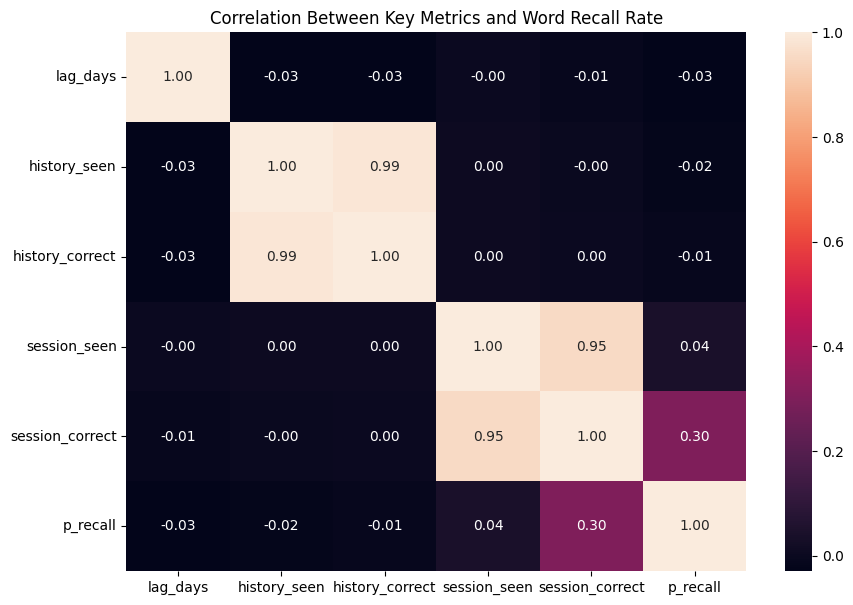

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,7))

sns.heatmap(
    correlation_data,
    annot=True,
    fmt='.2f'
)

plt.title("Correlation Between Key Metrics and Word Recall Rate")

plt.show()

## Outlier Detection

### Business Question
Are there extreme values in key metrics that could distort the Word Recall Rate analysis?

### Key Metrics
- lag_days
- history_seen
- p_recall
- avg_prior_exposures
- item_recall_rate

### Objective
Identify unusual values in important analytical variables before finalising the analysis.

In [ ]:
outlier_summary = df[
    ['lag_days', 'history_seen', 'p_recall']
].describe()

display(outlier_summary)

,lag_days,history_seen,p_recall
count,499436.000000,499436.000000,499436.000000
mean,8.426820,21.795071,0.896076
std,25.921927,132.212007,0.271270
min,0.000000,1.000000,0.000000
25%,0.006000,3.000000,1.000000
50%,0.895000,6.000000,1.000000
75%,5.128000,15.000000,1.000000
max,466.389000,13447.000000,1.000000


In [ ]:
outlier_summary_df3 = df3[
    [
        'avg_prior_exposures',
        'avg_session_recall',
        'item_recall_rate'
    ]
].describe()

display(outlier_summary_df3)

,avg_prior_exposures,avg_session_recall,item_recall_rate
count,6211.000000,6211.000000,6211.000000
mean,9.446493,0.887509,0.896661
std,17.119897,0.054209,0.047921
min,1.000000,0.459000,0.503300
25%,4.360000,0.857700,0.870500
50%,5.790000,0.895800,0.903300
75%,8.155000,0.925700,0.930600
max,395.540000,0.996700,0.995700


In [ ]:
def count_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return ((data[column] < lower) | (data[column] > upper)).sum()

for col in ['lag_days', 'history_seen', 'p_recall']:
    print(col, "outliers:", count_outliers(df, col))

lag_days outliers: 70303
history_seen outliers: 53633
p_recall outliers: 80659


## Data Cleaning and Preprocessing

### Business Objective
Prepare the datasets for reliable analysis by removing invalid or duplicate records and ensuring that key analytical variables are in the correct format.

### Cleaning Tasks
- Remove exact duplicate records.
- Check and handle missing values in important analytical columns.
- Validate recall values.
- Ensure numerical variables have appropriate data types.
- Preserve valid learner practice records.

In [ ]:
df_clean = df.copy()
df2_clean = df2.copy()
df3_clean = df3.copy()
forgetting_curve_clean = forgetting_curve_df.copy()

print("Clean datasets created successfully.")

Clean datasets created successfully.


### Duplicate Removal

Exact duplicate records can affect aggregate recall metrics.
Duplicate rows are removed from the analysis datasets.

In [ ]:
df_clean = df_clean.drop_duplicates().copy()
df2_clean = df2_clean.drop_duplicates().copy()
df3_clean = df3_clean.drop_duplicates().copy()
forgetting_curve_clean = forgetting_curve_clean.drop_duplicates().copy()

print("Duplicates removed.")

Duplicates removed.


### Recall Rate Validation

Word Recall Rate should be between 0 and 1 because it represents the proportion of correctly recalled attempts.

In [ ]:
invalid_recall = df_clean[
    (df_clean['p_recall'] < 0) |
    (df_clean['p_recall'] > 1)
]

print("Invalid p_recall records:", len(invalid_recall))

Invalid p_recall records: 0


### Numeric Data Validation

Check whether the main analytical variables are stored as numeric values.

In [ ]:
numeric_columns = [
    'lag_days',
    'history_seen',
    'history_correct',
    'session_seen',
    'session_correct',
    'p_recall'
]

display(df_clean[numeric_columns].dtypes)

,0
lag_days,float64
history_seen,int64
history_correct,int64
session_seen,int64
session_correct,int64
p_recall,float64


### Recall Rate Conversion for Presentation

Recall probabilities are converted from decimal format to percentage format to make the results easier to interpret.

In [ ]:
df_clean['recall_percentage'] = df_clean['p_recall'] * 100

df3_clean['recall_percentage'] = (
    df3_clean['item_recall_rate'] * 100
)

df2_clean['recall_percentage'] = (
    df2_clean['item_recall_rate'] * 100
)

print("Recall percentage columns created.")

Recall percentage columns created.


## EDA 1: Overall Word Recall Rate

### Business Question
What is the overall Word Recall Rate across all learner practice records?

### Objective
Establish the overall recall baseline before comparing recall across lag, exposure, language, part of speech, words, and courses.

### Metric
p_recall

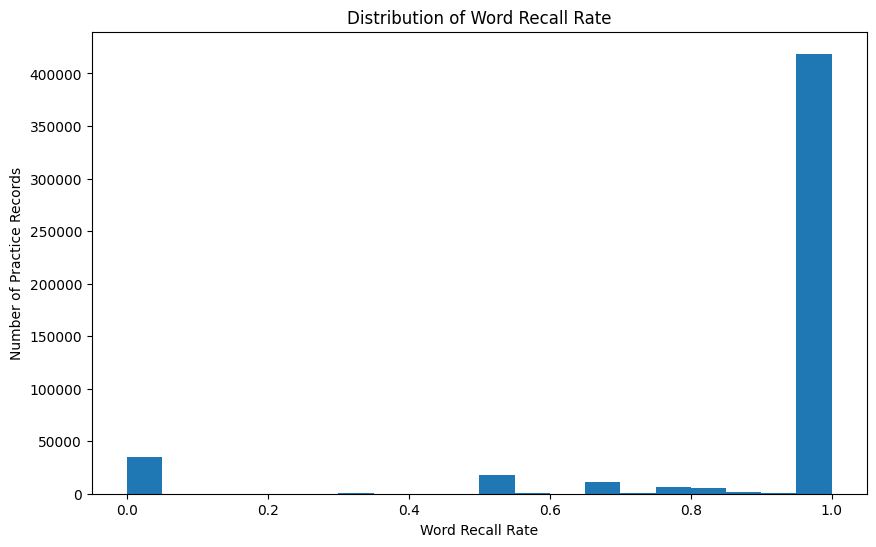

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.hist(
    df_clean['p_recall'].dropna(),
    bins=20
)

plt.xlabel("Word Recall Rate")
plt.ylabel("Number of Practice Records")
plt.title("Distribution of Word Recall Rate")

plt.show()

## EDA 3: Relationship Between Lag Days and Word Recall Rate

### Business Question
How does Word Recall Rate change as the time since the previous practice increases?

### Objective
Identify the recall decay pattern associated with longer practice gaps.

In [ ]:
lag_recall_eda = (
    df_clean.groupby(
        pd.cut(
            df_clean['lag_days'],
            bins=[0, 1, 3, 7, 14, 30, float('inf')],
            labels=[
                '0-1 day',
                '1-3 days',
                '3-7 days',
                '7-14 days',
                '14-30 days',
                '30+ days'
            ]
        ),
        observed=True
    )
    .agg(
        avg_recall=('p_recall', 'mean'),
        attempts=('session_seen', 'sum')
    )
    .reset_index()
)

display(lag_recall_eda)

,lag_days,avg_recall,attempts
0,0-1 day,0.906147,479348
1,1-3 days,0.891813,132342
2,3-7 days,0.888044,112472
3,7-14 days,0.881301,72304
4,14-30 days,0.881116,52673
5,30+ days,0.871610,58542


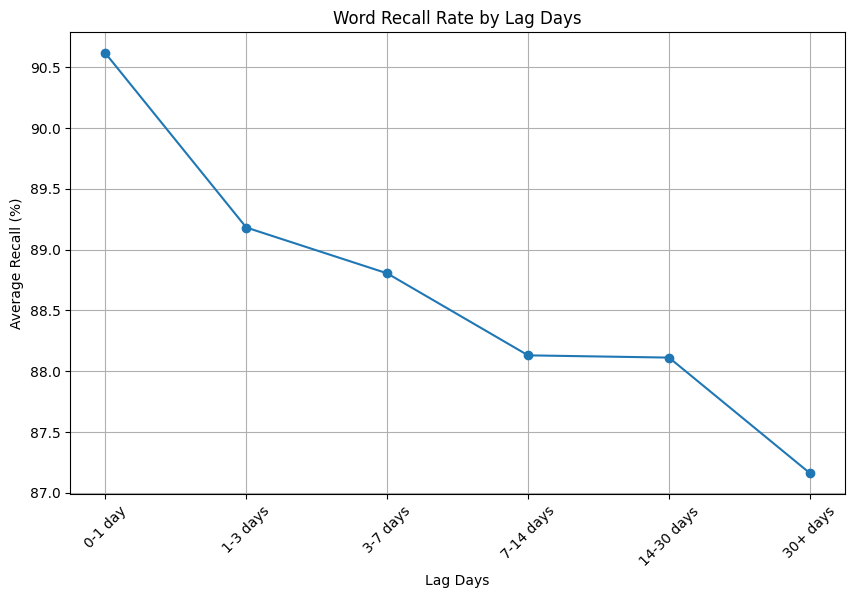

In [ ]:
plt.figure(figsize=(10,6))

plt.plot(
    lag_recall_eda['lag_days'].astype(str),
    lag_recall_eda['avg_recall'] * 100,
    marker='o'
)

plt.xlabel("Lag Days")
plt.ylabel("Average Recall (%)")
plt.title("Word Recall Rate by Lag Days")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

## EDA 4: Relationship Between Prior Exposure and Word Recall Rate

### Business Question
How does Word Recall Rate change with the number of previous exposures to a word?

### Objective
Understand whether repeated exposure is associated with stronger vocabulary retention.

In [ ]:
exposure_eda = (
    df_clean.groupby('history_seen', as_index=False)
    .agg(
        avg_recall=('p_recall', 'mean'),
        attempts=('session_seen', 'sum')
    )
    .sort_values('history_seen')
)

display(exposure_eda.head(20))

,history_seen,avg_recall,attempts
0,1,0.893790,33193
1,2,0.896370,78637
2,3,0.895412,123928
3,4,0.894377,94833
4,5,0.894864,69140
5,6,0.896442,57390
6,7,0.899841,44823
7,8,0.899842,39287
8,9,0.901000,32467
9,10,0.900148,27918
